# 07C — Phase 7 checkpoint: One-second event coverage from added MX history

ตรวจ opening/closing × SV × module จาก external canonical rows ที่ไม่ซ้ำ primary โดยใช้ clean-window rule เดียวกับ one-second analysis เดิม.

## tl;dr

พบ clean events 354 จาก candidate starts 3,378; closing 347, opening 7. ไม่มี context ใดถึงเกณฑ์ 30 events และ 3 วัน จึงยังไม่ปลดล็อก response profile, sequence model หรือ production.

## Context & Methods

Clean window ต้องเป็น Run, SV คงที่, ไม่มี MValveHome/Off/negative valve, มี status On ก่อน event, valve step ≥3 และไม่มี ChangeValve ซ้อนใน horizon −30 ถึง +120 วินาที. นี่เป็น coverage audit ไม่ใช่ fault diagnosis หรือ baseline approval.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'notebooks').exists(): PROJECT_ROOT=PROJECT_ROOT.parent
OUTPUT=PROJECT_ROOT/'notebooks/outputs/ht9046mx_external_event_coverage_v1'
FIGURES=OUTPUT/'figures'; FIGURES.mkdir(parents=True,exist_ok=True)
summary=json.loads((OUTPUT/'analysis_summary.json').read_text())
coverage=pd.read_csv(OUTPUT/'external_event_coverage_by_context.csv',dtype={'machine_number':str})
events=pd.read_parquet(OUTPUT/'external_clean_events.parquet')
print(summary)


{'source': 'external canonical novel rows only', 'partitions_scanned': 353, 'positive_intervals': 28213674, 'exact_1s': 27803213, 'two_seconds': 394520, 'gt_2s': 15941, 'candidate_starts': 3378, 'boundary_rejected': 10, 'clean_events': 354, 'machines_with_clean_events': 6, 'clean_events_by_direction': {'Closing': 347, 'Opening': 7}, 'contexts': 192, 'contexts_coverage_met': 0, 'limits': ['External canonical novel rows only; primary data not reprocessed', 'Source timezone and pressure units unconfirmed', 'No service/refill epoch, recipe/load, facility-water or technician labels', 'Coverage met is not candidate-profile or production approval']}


## Results

### 1. Funnel: ChangeValve starts → clean events

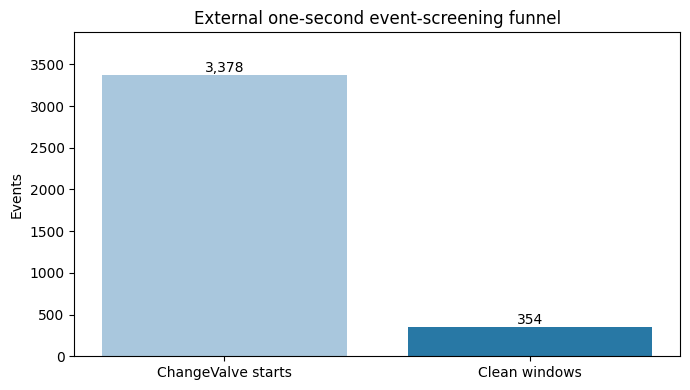

In [2]:
fig,ax=plt.subplots(figsize=(7,4)); values=[summary['candidate_starts'],summary['clean_events']]
bars=ax.bar(['ChangeValve starts','Clean windows'],values,color=['#A9C7DD','#2878A5'])
for b,v in zip(bars,values): ax.text(b.get_x()+b.get_width()/2,v,f'{v:,}',ha='center',va='bottom')
ax.set_title('External one-second event-screening funnel'); ax.set_ylabel('Events'); ax.set_ylim(0,max(values)*1.15)
fig.tight_layout(); fig.savefig(FIGURES/'01_event_funnel.png',dpi=180,bbox_inches='tight'); plt.show()


### 2. Direction balance
Valve-command direction is not refrigerant-flow direction.

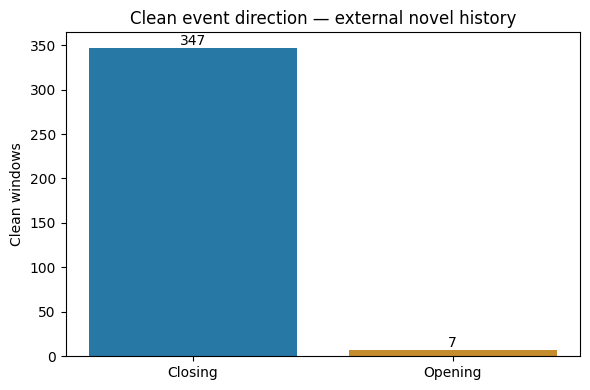

In [3]:
s=events.direction.value_counts().reindex(['Closing','Opening'],fill_value=0)
fig,ax=plt.subplots(figsize=(6,4)); bars=ax.bar(s.index,s.values,color=['#2878A5','#C48C2D'])
for b,v in zip(bars,s.values): ax.text(b.get_x()+b.get_width()/2,v,f'{v:,}',ha='center',va='bottom')
ax.set_title('Clean event direction — external novel history'); ax.set_ylabel('Clean windows')
fig.tight_layout(); fig.savefig(FIGURES/'02_direction_balance.png',dpi=180,bbox_inches='tight'); plt.show()


### 3. Best-supported context: SV Off / Closing
No cross-SV or direction pooling.

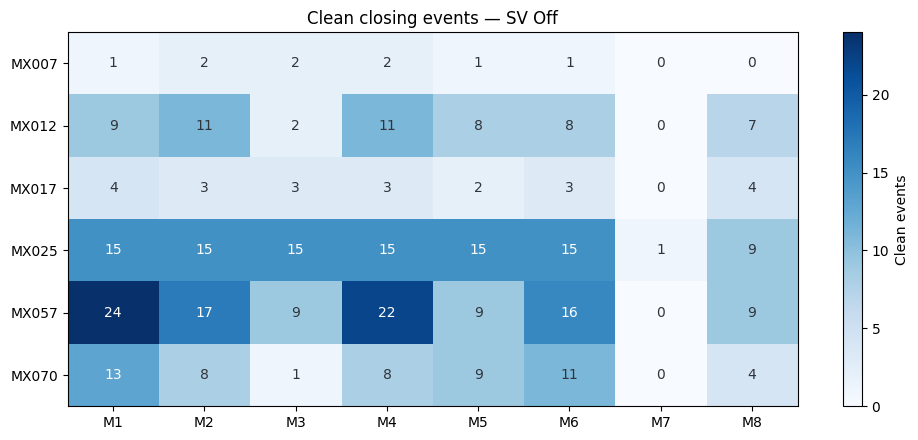

In [4]:
p=(coverage.query("sv=='Off' and direction=='Closing'").pivot(index='machine_number',columns='module',values='clean_events').reindex(columns=range(1,9)).fillna(0))
fig,ax=plt.subplots(figsize=(10,4.5)); im=ax.imshow(p.to_numpy(),cmap='Blues',aspect='auto')
for i in range(len(p)):
 for j in range(8): ax.text(j,i,str(int(p.iloc[i,j])),ha='center',va='center',color='white' if p.iloc[i,j]>p.to_numpy().max()/2 else '#30343B')
ax.set_xticks(range(8),[f'M{i}' for i in range(1,9)]); ax.set_yticks(range(len(p)),['MX'+m for m in p.index]); ax.set_title('Clean closing events — SV Off')
fig.colorbar(im,ax=ax,label='Clean events'); fig.tight_layout(); fig.savefig(FIGURES/'03_closing_off_coverage.png',dpi=180,bbox_inches='tight'); plt.show()


## QA and decision

In [5]:
qa={'count_matches':len(events)==summary['clean_events'],'unique_event_key':not events.duplicated(['machine_number','module','event_at']).any(),'no_approval_status':set(coverage.coverage_status).issubset({'INSUFFICIENT_COVERAGE','COVERAGE_MET_NOT_APPROVED'}),'opening_limited':int((events.direction=='Opening').sum())<30}
assert all(qa.values()),qa
(OUTPUT/'notebook_qa.json').write_text(json.dumps(qa,indent=2))
pd.Series(qa,name='Passed').to_frame()


,Passed
count_matches,True
unique_event_key,True
no_approval_status,True
opening_limited,True


## Takeaway

ข้อมูลเพิ่มช่วยเพิ่ม closing evidence แต่ opening และ SV On ยังไม่พอ. ขั้นถัดไปคือรวม coverage counts กับ primary โดยไม่รวม raw rows ซ้ำ, ตรวจ service/refill epoch และ predeclare split ใหม่ก่อน retrain หรือ server shadow replay.